# 04. Effect by context
**Goal**: Find the situations in which notifications actually increase steps. Fit the model that reproduced the paper in 03 separately in each situation, and get the effect and its confidence interval. The results are the basis for the timing proposals in 07.

**Why walking notifications**: In section 4 of 03, the effect came mostly from walking notifications (+23.5% vs +2.9% for anti-sedentary). Combining the two would dilute it, so the main analysis is walking vs no notification; section 5 compares the other cases.

**Questions**
1. How large is the effect of walking notifications in each situation?
2. Are the differences between situations statistically confirmed?
3. Do they hold with missing values left out?
4. Do the patterns look the same for all notifications and for anti-sedentary notifications?

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", None)

# This notebook lives in notebooks/, so the project folder is one level up.
PROJECT_DIR = Path("..")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

BLUE = "#2a78d6"
GREY = "#9a9893"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
})

decision_points = pd.read_csv(PROCESSED_DIR / "decision_points.csv")
print(decision_points.shape)

(8274, 31)


### 0.1. Analysis sample and context variables
- `slot_label`, `day_type`: Same as in 02.
- `phone_in_use`: Whether an app was open on the phone at the decision point (`screen_on`).
- `location`, `weather_group`: Used as built in 01.

Build the same sample as in 03 (available, not a travel day) and give the context variables readable labels.

In [2]:
sample = decision_points[(decision_points["available"] == 1) & (decision_points["travel_day"] == 0)].copy()

sample["slot_label"] = sample["slot"].astype(str) + " " + sample["slot_name"]
sample["day_type"] = sample["is_weekend"].map({0: "weekday", 1: "weekend"})
sample["phone_in_use"] = sample["screen_on"].map({0: "not in use", 1: "in use"})

sample["active"] = (sample["send_type"] == "active").astype(int)
sample["sedentary"] = (sample["send_type"] == "sedentary").astype(int)

walk_vs_none = sample[sample["send_type"].isin(["active", "none"])]
sedentary_vs_none = sample[sample["send_type"].isin(["sedentary", "none"])]

print(f"Sample: {len(sample)} rows, {sample['user_id'].nunique()} participants")
print(f"Walking vs none: {len(walk_vs_none)} rows")

Sample: 6331 rows, 37 participants
Walking vs none: 4675 rows


### 0.2. Functions
- `fit_gee`: Same as in 03.
- `effect_by_group`: For each value of a context variable (e.g. lunch), keep only those rows, fit `outcome ~ steps before + notification`, and summarize the effect in one row. Randomization happened in every situation (section 1 of 02), so the comparison within a situation still reads as an effect.
- `difference_p`: Tests in one step whether the effect **differs** by situation (explained in section 3).

`OUTCOME` and `PRE` are the version with missing steps set to 0, as in 03. The functions also accept them as inputs so section 4 can pass the other version.

In [3]:
OUTCOME = "log_steps_post30_zero"
PRE = "log_steps_pre30_zero"


def fit_gee(formula, data):
    model = smf.gee(
        formula,
        groups="user_id",                         # standard errors per participant
        data=data,
        cov_struct=sm.cov_struct.Independence(),
        missing="drop",                           # skip rows with a missing value in the formula
    )
    result = model.fit(cov_type="bias_reduced")   # small-sample correction
    ci = result.conf_int()
    table = pd.DataFrame({
        "estimate": result.params,
        "std_err": result.bse,
        "p_value": result.pvalues,
        "ci_low": ci[0],
        "ci_high": ci[1],
    })
    return table.round(3)


def effect_by_group(data, context, treatment, outcome=OUTCOME, pre=PRE):
    rows = []
    for group, subset in data.groupby(context):           # rows with a missing context are skipped
        table = fit_gee(f"{outcome} ~ {pre} + {treatment}", subset)
        rows.append({
            "context": context,
            "group": group,
            "n_rows": len(subset),
            "participants": subset["user_id"].nunique(),
            "estimate": table.loc[treatment, "estimate"],
            "p_value": table.loc[treatment, "p_value"],
            "ci_low": table.loc[treatment, "ci_low"],
            "ci_high": table.loc[treatment, "ci_high"],
        })
    result = pd.DataFrame(rows)
    for col in ["estimate", "ci_low", "ci_high"]:
        result[f"{col}_pct"] = ((np.exp(result[col]) - 1) * 100).round(1)
    return result


def difference_p(data, context, treatment, outcome=OUTCOME, pre=PRE):
    formula = f"{outcome} ~ {pre} + C({context}) + {treatment} + {treatment}:C({context})"
    model = smf.gee(formula, groups="user_id", data=data,
                    cov_struct=sm.cov_struct.Independence(), missing="drop")
    result = model.fit(cov_type="bias_reduced")
    tests = result.wald_test_terms(skip_single=False, scalar=True).table
    return tests.loc[f"{treatment}:C({context})", "pvalue"]

In [4]:
overall = fit_gee(f"{OUTCOME} ~ {PRE} + active", walk_vs_none).loc["active"]
overall_pct = (np.exp(overall["estimate"]) - 1) * 100
print(f"Walking notifications overall: {overall_pct:+.1f}% (p = {overall['p_value']:.3f})")

Walking notifications overall: +23.6% (p = 0.011)


## 1. Context Variables
All are known **before** the notification is sent. Information created after the notification (such as the response) could not be used by the app to decide when to send, and would bias the result (data leakage).

| 변수 / Variable | 값 / Values | 알림 정책에서의 의미 / Meaning for notification policy |
| --- | --- | --- |
| `slot_label` | 하루 5개 시간대 / 5 slots per day | 몇 시에 보낼까 / What time to send |
| `day_type` | 평일, 주말 / weekday, weekend | 요일에 따라 다르게 할까 / Treat weekends differently? |
| `location` | 집, 직장, 그 외 / home, work, other | 어디에 있을 때 보낼까 / Where the user is |
| `weather_group` | 맑음, 흐림, 강수 / clear, cloudy, precipitation | 날씨가 나쁘면 보내지 말까 / Skip bad weather? |
| `phone_in_use` | 사용 중, 사용 안 함 / in use, not in use | 휴대폰을 쓰고 있을 때 보낼까 / Send while the phone is in use? |

First check that each value has enough walking and no-notification decision points.

In [5]:
CONTEXTS = ["slot_label", "day_type", "location", "weather_group", "phone_in_use"]

for context in CONTEXTS:
    print(pd.crosstab(walk_vs_none[context].fillna("missing"), walk_vs_none["send_type"]))
    print()

send_type          active  none
slot_label                     
1 morning commute     498   552
2 lunch               345   538
3 mid-afternoon       415   520
4 evening commute     420   461
5 after dinner        421   505

send_type  active  none
day_type               
weekday      1506  1862
weekend       593   714

send_type  active  none
location               
home          544   717
missing        44    29
other        1167  1438
work          344   392

send_type      active  none
weather_group              
clear             709   810
cloudy           1237  1597
missing            48    51
precipitation     105   118

send_type     active  none
phone_in_use              
in use           411   518
not in use      1688  2058



- Every value has both groups; only precipitation is small (223 in total).
- The 73 rows with no location and 99 with no weather drop out only of that variable's analysis (`groupby` skips missing values).

---

## 2. Effect of walking notifications by context
- Run `effect_by_group` for each context variable and stack the results. 
- `estimate_pct` is how many percent more steps follow a walking notification in that situation; `ci_low_pct` to `ci_high_pct` is the 95% confidence interval.

In [6]:
walk_effects = pd.concat(
    [effect_by_group(walk_vs_none, context, "active") for context in CONTEXTS],
    ignore_index=True,
)
walk_effects[["context", "group", "n_rows", "participants", "estimate_pct", "ci_low_pct", "ci_high_pct", "p_value"]]

,context,group,n_rows,participants,estimate_pct,ci_low_pct,ci_high_pct,p_value
0,slot_label,1 morning commute,1050,37,-1.1,-27.5,34.7,0.943
1,slot_label,2 lunch,883,37,75.6,22.8,150.9,0.002
2,slot_label,3 mid-afternoon,935,37,24.1,-18.8,89.6,0.318
3,slot_label,4 evening commute,881,37,20.4,-14.4,69.2,0.285
4,slot_label,5 after dinner,926,37,29.3,-9.7,85.0,0.160
5,day_type,weekday,3368,37,31.5,9.1,58.6,0.004
6,day_type,weekend,1307,37,9.0,-18.6,45.9,0.563
7,location,home,1261,26,41.9,9.1,84.6,0.009
8,location,other,2605,37,5.1,-13.7,28.0,0.621
9,location,work,736,28,65.5,-7.1,194.8,0.087


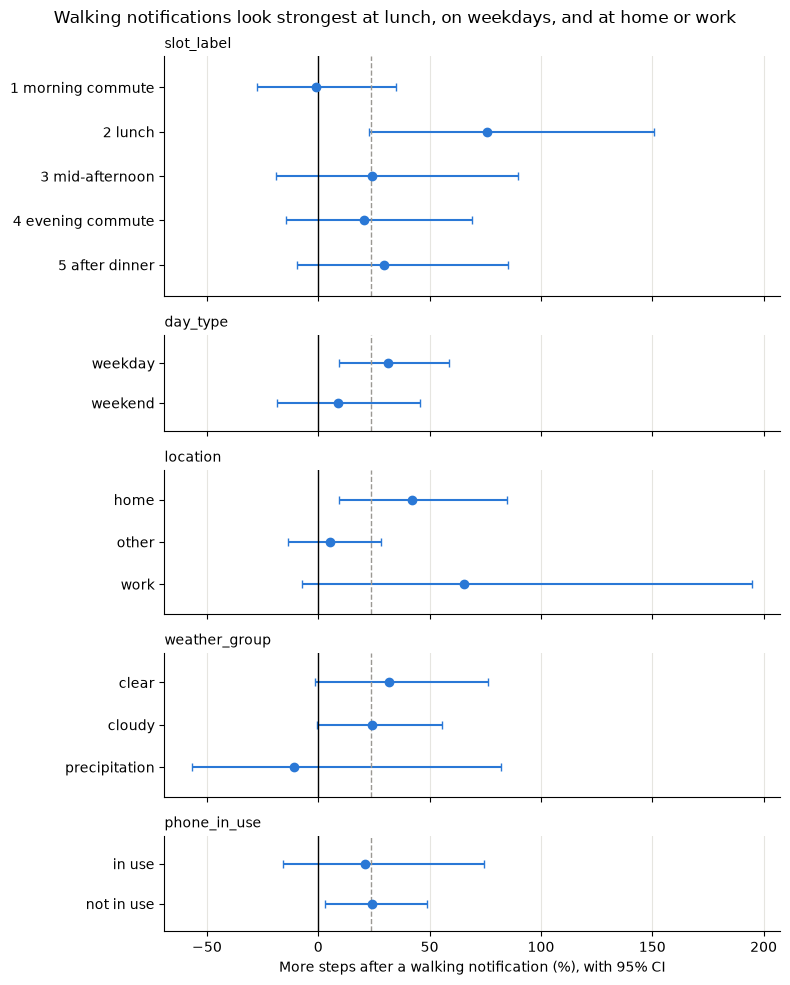

In [7]:
n_groups = walk_effects.groupby("context", sort=False).size()
fig, axes = plt.subplots(len(CONTEXTS), 1, figsize=(8, 10), sharex=True,
                         gridspec_kw={"height_ratios": n_groups.values})

for ax, context in zip(axes, CONTEXTS):
    rows = walk_effects[walk_effects["context"] == context]
    y = np.arange(len(rows))[::-1]                      # first group at the top
    error = [rows["estimate_pct"] - rows["ci_low_pct"], rows["ci_high_pct"] - rows["estimate_pct"]]
    ax.errorbar(rows["estimate_pct"], y, xerr=error, fmt="o", color=BLUE, capsize=3)
    ax.axvline(0, color="black", linewidth=1)
    ax.axvline(overall_pct, color=GREY, linestyle="--", linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(rows["group"])
    ax.set_ylim(-0.7, len(rows) - 0.3)
    ax.set_title(context, loc="left", fontsize=10)
    ax.grid(axis="y", visible=False)

axes[-1].set_xlabel("More steps after a walking notification (%), with 95% CI")
fig.suptitle("Walking notifications look strongest at lunch, on weekdays, and at home or work")
plt.tight_layout()
plt.show()

In the chart, each dot is the effect and the line is its 95% confidence interval. If the line crosses 0 (black), an effect in that situation is not certain. The grey dashed line is the overall effect.

### What section 2 shows
- **Time slot**: lunch has the largest effect (+75.6%, p = 0.002), with a confidence interval above 0. The morning commute shows none (-1.1%). The other slots are +20-29%, with intervals that cross 0.
- **Day**: weekdays +31.5% (p = 0.004), weekends +9.0% (p = 0.563).
- **Location**: home +41.9% (p = 0.009), work +65.5% (p = 0.087, 28 participants), other +5.1%, matching 03.
- **Weather**: clear and cloudy are similar (+24-32%); precipitation is -11.0%, but with few rows the interval is very wide.
- **Phone use**: in use +21.2% and not in use +24.0%, almost the same.

---

## 3. Are the differences confirmed?
"Lunch is significant and the morning is not" does not mean "lunch and the morning differ"; the difference must be tested directly. `difference_p` puts all `notification x context` terms in one model and tests **whether they are all 0** (= the effect is the same in every situation) in one step (Wald test). A small p-value means the effect differs by situation.

In [8]:
differences = pd.Series({context: difference_p(walk_vs_none, context, "active") for context in CONTEXTS}, name="p_value")
differences.round(3)

slot_label       0.334
day_type         0.210
location         0.107
weather_group    0.574
phone_in_use     0.917
Name: p_value, dtype: float64

- All five variables have p > 0.1. The differences in section 2 are **not statistically confirmed**.
- With only 37 participants, splitting by situation leaves little information per group. This is not evidence of no difference, only too little data to confirm one.
- Section 3 of 03 used two location values (home or work vs other) and got p = 0.037; with three values here, the test is weaker (p = 0.107).
- Treat section 2 as **likely candidates, not confirmed conclusions**. The proposals in 07 are framed as candidates to test.

---

## 4. Sensitivity analysis
Recompute section 2 with missing steps left out, and compare effects (%) and p-values.

In [9]:
walk_effects_left_out = pd.concat(
    [effect_by_group(walk_vs_none, context, "active", outcome="log_steps_post30", pre="log_steps_pre30")
     for context in CONTEXTS],
    ignore_index=True,
)

sensitivity = walk_effects[["context", "group", "estimate_pct", "p_value"]].merge(
    walk_effects_left_out[["context", "group", "estimate_pct", "p_value"]],
    on=["context", "group"],
    suffixes=("_missing_0", "_left_out"),
)
sensitivity

,context,group,estimate_pct_missing_0,p_value_missing_0,estimate_pct_left_out,p_value_left_out
0,slot_label,1 morning commute,-1.1,0.943,-5.9,0.717
1,slot_label,2 lunch,75.6,0.002,87.0,0.001
2,slot_label,3 mid-afternoon,24.1,0.318,30.2,0.260
3,slot_label,4 evening commute,20.4,0.285,14.5,0.427
4,slot_label,5 after dinner,29.3,0.160,31.3,0.139
5,day_type,weekday,31.5,0.004,32.0,0.009
6,day_type,weekend,9.0,0.563,9.2,0.597
7,location,home,41.9,0.009,34.6,0.056
8,location,other,5.1,0.621,6.8,0.527
9,location,work,65.5,0.087,75.4,0.089


- Lunch (+87.0%, p = 0.001) and weekdays (+32.0%, p = 0.009) stay large and significant. **These are the most reliable results.**
- The morning commute (-5.9%) and weekends (+9.2%) show little effect in both versions.
- Home drops to +34.6% (p = 0.056); as in 03, the location result is weak.

---

## 5. Comparison across notification types
Repeat the analysis for all notifications (`sent`, any type) and for anti-sedentary notifications (`sedentary`), and put the effects (%) side by side. Section 2.2 of 02 was a simple comparison of all notifications.

In [10]:
treatments = {
    "walking": ("active", walk_vs_none),    # 걷기 알림 + 안 보냄
    "any": ("sent", sample),    # 전체 표본
    "anti-sedentary": ("sedentary", sedentary_vs_none),     # 앉아 있기 줄이기 알림 + 안 보냄
}

by_type = []
for name, (treatment, data) in treatments.items():
    for context in CONTEXTS:
        table = effect_by_group(data, context, treatment)
        table["notification"] = name
        by_type.append(table)
by_type = pd.concat(by_type, ignore_index=True)

by_type.pivot_table(index=["context", "group"], columns="notification", values="estimate_pct", sort=False)

notification                     walking   any  anti-sedentary
context       group                                           
slot_label    1 morning commute     -1.1   4.9            15.3
              2 lunch               75.6  20.7           -16.2
              3 mid-afternoon       24.1  27.5            31.7
              4 evening commute     20.4   7.8            -8.1
              5 after dinner        29.3  10.6           -10.0
day_type      weekday               31.5  23.7            14.0
              weekend                9.0  -3.7           -17.1
location      home                  41.9  24.0             5.8
              other                  5.1   6.7             8.5
              work                  65.5  22.3           -16.1
weather_group clear                 31.7  29.3            26.4
              cloudy                24.2  12.1            -1.4
              precipitation        -11.0 -25.2           -39.9
phone_in_use  in use                21.2  11.5            -1.2
              not in use            24.0  14.1             2.9

- With all notifications, effects shrink: lunch is +75.6% for walking but +20.7% for any notification, because anti-sedentary notifications dilute it.
- Anti-sedentary notifications show no clear effect in any situation (p > 0.1 in every group).
- On weekends, no notification type increases steps (any: -3.7%, anti-sedentary: -17.1%).
- -> Notification type must be separated when looking at context. 07 proposes what to send as well as when.

## 6. Summary
| 상황 / Context | 걷기 알림 효과 / Walking effect | 근거 / Evidence | 07에서 검토할 제안 / Candidate for 07 |
| --- | --- | --- | --- |
| 점심 / Lunch | +75.6% | 강함: 두 버전 모두 유의 / Strong: significant in both versions | 걷기 알림을 우선 배치 / Prioritize walking notifications |
| 평일 / Weekdays | +31.5% | 강함: 두 버전 모두 유의 / Strong: significant in both versions | 평일 중심으로 보냄 / Focus on weekdays |
| 아침 출근 / Morning commute | −1.1% | 두 버전 모두 효과 없음 / No effect in either version | 줄이거나 보내지 않음 / Reduce or skip |
| 주말 / Weekends | +9.0% | 어떤 알림도 효과 없음 / No effect for any type | 줄이거나 내용을 바꿈 / Reduce or change the content |
| 집·직장 / Home or work | +41.9%, +65.5% | 약함: 결측 처리에 따라 달라짐 / Weak: depends on missing-value handling | 장소 정보가 있을 때 보조 기준 / Secondary rule when location is known |
| 비·눈 / Precipitation | −11.0% | 매우 약함: 223건 / Very weak: 223 rows | 판단 보류 / No decision |
| 휴대폰 사용 / Phone in use | 차이 없음 / No difference | – | 기준으로 쓰지 않음 / Not used as a rule |

**한계 / Limitations**
- Differences between situations were not confirmed by the tests in section 3; 37 participants give limited power.
- Each context was examined on its own; combining two (e.g. weekday lunch) would make groups even smaller and estimates unstable.
- The effect declines over time (section 2 of 03); the effects here average over the whole study.

**Next**: 05 looks at engagement in the same situations and checks whether high engagement and large effects coincide. 07 combines 03 (decline over time) and 04 (effect by context) into proposals on notification timing and frequency.